# Compute frontiers, compute-optimal N / D and the prior ablation (Figures 1-3)

* **Figure 1**: compute frontier per metric with the fitted law $L(C) = A C^{-\alpha} + L_0$, and the frontier runs
  in the (parameters, total cells) plane.
* **Figure 2**: power laws of parameters and total cells against compute on each metric's frontier.
* **Figure 3**: frontiers of the narrow prior (4 features x 100 rows), the wide prior (16 x 400) and the scaled prior,
  and the prior size against compute.

Laws are fitted on grid points up to $10^{16}$ FLOPs; the budgets up to $10^{17}$ FLOPs are held out (Table 3,
`paper_tables.py`). Figures go to `figures/`.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

from scaling.utils import double_sigmoid_functional_form, fit_linear_model, fit_parametric_form, functional_form_L0

sns.set_style("white")


# Data Loading


In [2]:
save_path = Path.cwd() / "figures"
save_path.mkdir(parents=True, exist_ok=True)


df = pd.read_csv("../data/nanotabpfn_model_tabiclv1_prior.csv", index_col=[0, 1])
config_columns = [col for col in df.columns if col.startswith('config/')]
print("config columns: ", config_columns)
loss_columns = ['real_data/nll', 'real_data/roc_auc', 'val/val_loss', 'val/small/val_loss', 'val/medium/val_loss']
loss_columns_extended = loss_columns + ['real_data/accuracy', 'real_data/balanced_accuracy']

print(f"{df['total_flops_rounded'].min():.2e}", df['total_flops_rounded'].max())

# Scaling laws are fitted on the grid points up to 1e16 FLOPs; the grid points from 1.78e16 to 1e17 FLOPs are held out
# (`extrapolation_df`, red markers) and only used to judge the extrapolation (paper Table 3).
FILTER_FLOPS_MAX = 1.00000000e+16 * 1.05
FILTER_FLOPS_MIN = 1.00000000e+11 * 0.95
extrapolation_df = df[FILTER_FLOPS_MAX < df['total_flops_rounded']]
df = df[(FILTER_FLOPS_MAX > df['total_flops_rounded']) & (df['total_flops_rounded'] > FILTER_FLOPS_MIN)]

print(f"{FILTER_FLOPS_MIN:.2e}", f"{FILTER_FLOPS_MAX:.2e}")


config columns:  ['config/effective_batch_size', 'config/lr', 'config/max_features', 'config/model_config.embedding_size', 'config/model_config.num_attention_heads', 'config/model_config.num_layers', 'config/num_datapoints_max', 'config/num_flops_training', 'config/weight_decay']
1.78e+11 1e+17
9.50e+10 1.05e+16


# Scaling Trends


In [3]:
def get_pareto_frontier(
        df: pd.DataFrame,
        x_name="flops",
        y_name="Validation Loss",
        minimization=True,
) -> pd.DataFrame:
    """ Function to compute Pareto over FLOPs.
    """
    # NOTE: strict assumption here that x_name is maximized and y_name is minimized
    df_copy = df.copy()
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    df_sorted = df_copy.sort_values(by=[x_name, y_name], ascending=[True, True])
    df_sorted = df_sorted.drop_duplicates(subset=[x_name], keep="first")
    pareto_points = []
    min_loss_so_far = float('inf')
    for _, row in df_sorted.iterrows():
        if row[y_name] < min_loss_so_far:
            pareto_points.append(row)
            min_loss_so_far = row[y_name]

    df_copy = pd.DataFrame(pareto_points)
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    return df_copy


def get_optimal_values(
        df: pd.DataFrame,
        x_name="flops",
        y_name="Validation Loss",
        minimization=True,
) -> pd.DataFrame:
    df_copy = df.copy()
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    df_sorted = df_copy.sort_values(by=[x_name, y_name], ascending=[True, True])
    df_optimal = df_sorted.drop_duplicates(subset=[x_name], keep="first")
    if not minimization:
        df_optimal[y_name] = - df_optimal[y_name]
    return df_optimal


In [4]:
FLOP_VALUES = np.array([
    1.00000000e+11, 1.77827941e+11, 3.16227766e+11, 5.62341325e+11,
    1.00000000e+12, 1.77827941e+12, 3.16227766e+12, 5.62341325e+12,
    1.00000000e+13, 1.77827941e+13, 3.16227766e+13, 5.62341325e+13,
    1.00000000e+14, 1.77827941e+14, 3.16227766e+14, 5.62341325e+14,
    1.00000000e+15, 1.77827941e+15, 3.16227766e+15, 5.62341325e+15,
    1.00000000e+16, 1.77827941e+16, 3.16227766e+16, 5.62341325e+16,
    1.00000000e+17, 1.77827941e+17, 3.16227766e+17, 5.62341325e+17,
    1.00000000e+18, 1.77827941e+18, 3.16227766e+18, 5.62341325e+18,
    1.00000000e+19
])


In [5]:
# Add additional columns to analyse
df['prior_max_cells'] = df['config/max_features'] * df['config/num_datapoints_max']
df['aspect_ratio'] = df['config/model_config.embedding_size'] / df['config/model_config.num_layers']
df['prior_ratio'] = df['config/num_datapoints_max'] / df['config/max_features']

flops_column = 'total_flops_rounded'

trend_columns = config_columns + ["parameters", "total_cells"] + [
    "prior_max_cells", "aspect_ratio", "prior_ratio"
]

# --- Consistent styling per metric ------------------------------------------------
# The two metric families are encoded twice on purpose: warm hues + solid lines for the
# metrics measured on *real data*, cool hues + dashed lines for the metrics measured on
# the *prior validation* sets. The grouping therefore survives greyscale printing and
# colour-vision deficiency, while the hue still identifies the individual metric.
# (Palette checked for lightness band, chroma floor, and CVD / normal-vision separation.)


LOSS_FAMILIES = {
    "real_data": "Real Data",
    "val": "In-Prior validation",
}

# The fits within one family come out almost coincident, so the line widths taper in
# drawing order: the later, thinner line stays visible as a core inside the earlier one.
LOSS_STYLES = {
    'real_data/nll':       {"color": "#d1121f", "linestyle": "-",  "linewidth": 4.5, "label": "NLL"},
    'real_data/roc_auc':   {"color": "#e07b00", "linestyle": "-",  "linewidth": 1.8, "label": "ROC AUC"},
    'val/val_loss':        {"color": "#2a78d6", "linestyle": "--", "linewidth": 5.0, "label": "val loss"},
    'val/small/val_loss':  {"color": "#1baf7a", "linestyle": "--", "linewidth": 3.0, "label": "val loss (small)"},
    'val/medium/val_loss': {"color": "#4a3aa7", "linestyle": "--", "linewidth": 1.4, "label": "val loss (medium)"},
}

def loss_family(loss_column):
    """'real_data' or 'val' -- the family a loss column belongs to."""
    return loss_column.split("/")[0]

def loss_style(loss_column, **overrides):
    """Style kwargs for a loss column, e.g. ax.plot(x, y, **loss_style(col, alpha=0.8))."""
    style = dict(LOSS_STYLES[loss_column])
    style.update(overrides)
    return style

def family_legends(ax, columns=None, locs=("upper left", "lower right"), **legend_kwargs):
    """Draw one legend box per metric family so the real-data / prior-val split is explicit."""
    columns = loss_columns if columns is None else columns
    kwargs = dict(fontsize="x-small", title_fontsize="small", framealpha=0.9)
    kwargs.update(legend_kwargs)
    for (family, title), loc in zip(LOSS_FAMILIES.items(), locs):
        handles = [
            Line2D([], [], **loss_style(col, linewidth=min(LOSS_STYLES[col]["linewidth"], 3.0)))
            for col in columns if loss_family(col) == family
        ]
        if not handles:
            continue
        ax.add_artist(ax.legend(handles=handles, title=title, loc=loc, **kwargs))


In [6]:
custom_metrics = ['val/val_loss', 'real_data/nll', 'real_data/roc_auc']
custom_labels = {
    'val/val_loss': 'Synthetic: Loss',
    'real_data/nll': 'Real: NLL',
    'real_data/roc_auc': 'Real: ROC AUC'
}


## Figure 1: compute frontiers and the (N, D) plane


val/val_loss
[-0.53378822  0.95877302 -0.06795716]
irreducible loss:  0.5863794226024645
  parameters   = 0.0795 * FLOPs^0.3805   R2=0.901
  total_cells  = 13.7 * FLOPs^0.5435   R2=0.949


real_data/nll
[-12.76565684   1.15639217  -0.06124705]
irreducible loss:  2.857233111856262e-06
  parameters   = 5.58 * FLOPs^0.2523   R2=0.840
  total_cells  = 0.135 * FLOPs^0.6745   R2=0.973


real_data/roc_auc
[-2.16513947  4.67318025 -0.23267182]
irreducible loss:  0.885266068001738
  parameters   = 53.9 * FLOPs^0.1923   R2=0.668
  total_cells  = 0.0368 * FLOPs^0.7096   R2=0.962


Saving /Users/hogj/Documents/tabular/tfm-scaling-laws/playground/figures/pareto_fits_with_nd.pdf


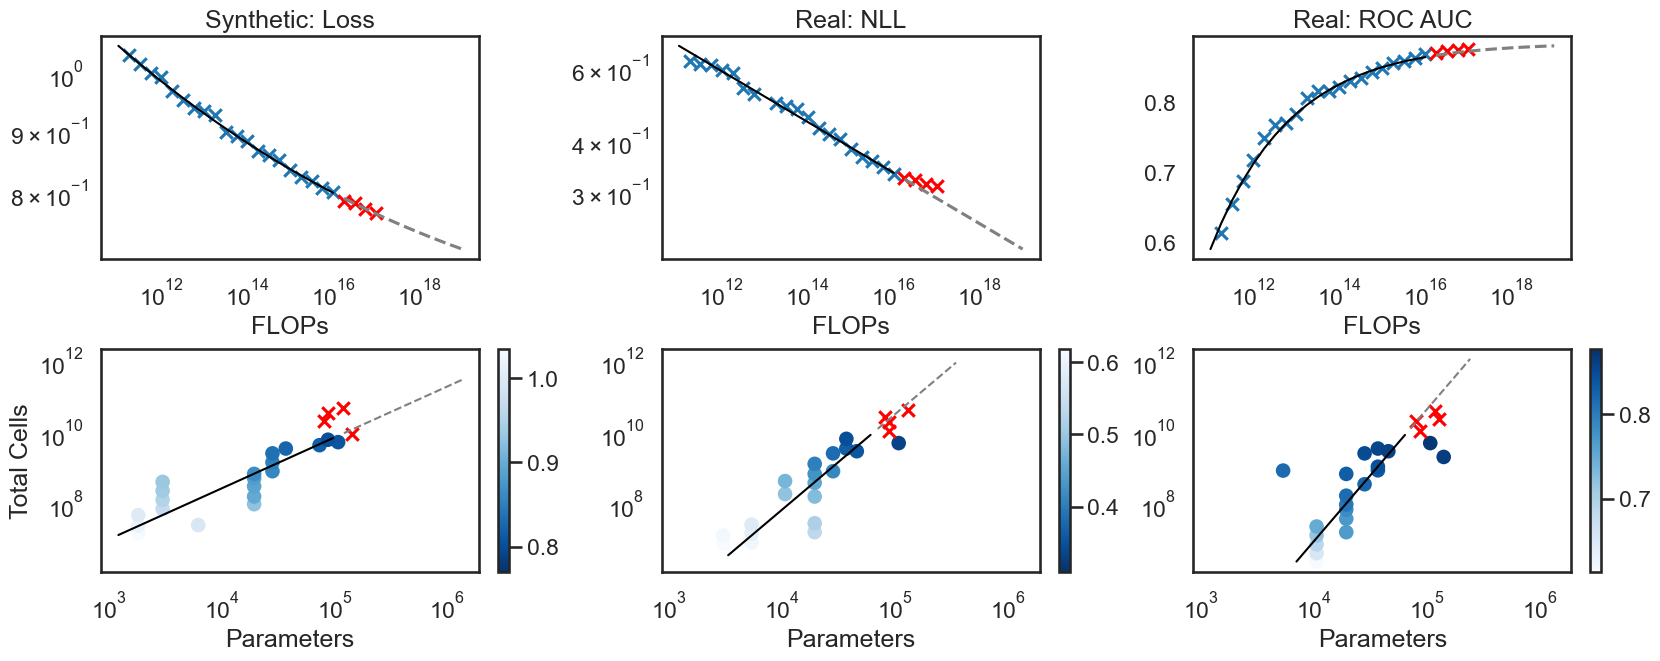

In [7]:
# Scaling laws on loss for the different metrics
param_names = {0: "L0", 1: "a", 2: "alpha"}

initial_grid_min = [
    [0, 0.1, 0.5],
    [0.1, 1, 2, 5, 10, 50, 100],
    [-1, -0.5, 0, 0.5, 1]
]
# Big-prior ROC AUC is S-shaped: a plateau, a sharp rise near 2e13 FLOPs, then a slow rise that levels off.
# double_sigmoid_functional_form: a sharp logistic step plus a broad one, all parameters fitted.
initial_grid_double_sigmoid = [
    [0.45, 0.5],                       # a_min   (floor)
    [0.15, 0.2],                       # h1      (height of the sharp step)
    [13.3],                            # x1      (log10 FLOPs of the sharp step)
    [5, 10],                           # k1      (steepness per decade)
    [0.15, 0.25, 0.35],                # h2      (height of the broad step)
    [12.5, 13.5, 14.5],                # x2      (log10 FLOPs of the broad step)
    [0.3, 0.6, 1.0],                   # k2      (steepness per decade)
]
bounds_double_sigmoid = [(0.3, 0.6), (0, 0.5), (12, 15), (0.5, 50), (0, 0.5), (10, 18), (0.01, 5)]

sns.set_context("talk")


n_cols = len(custom_metrics)
fig, axes = plt.subplots(2, n_cols, layout='constrained', figsize=(5.5 * n_cols, 6.5), squeeze=False)

for ax_prior in axes[1, 1:]:
    ax_prior.sharex(axes[1, 0])
    ax_prior.sharey(axes[1, 0])

for loss_idx, loss_column in enumerate(custom_metrics):
    ax, ax_nd = axes[0, loss_idx], axes[1, loss_idx]

    maximization = "roc_auc" in loss_column or "accuracy" in loss_column
    minimization = not maximization
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)
    pareto_extrapolation = get_pareto_frontier(extrapolation_df, flops_column, loss_column, minimization=minimization)

    ax.scatter(pareto[flops_column], pareto[loss_column], marker='x')
    ax.scatter(pareto_extrapolation[flops_column], pareto_extrapolation[loss_column], marker='x', color='red')

    initial_grid = initial_grid_min
    bounds = None
    func_form = functional_form_L0

    X_data = pareto[flops_column].values
    y_data = np.log(pareto[loss_column].values) if minimization else np.log(1-pareto[loss_column].values)

    best_params, best_loss = fit_parametric_form(
        func_form=func_form,
        x_data=X_data,
        y_data=y_data,
        initial_grid=list(product(*initial_grid)),
        bounds=bounds,
        delta=1e-3,
    )
    print(loss_column)
    print(best_params)
    print("irreducible loss: ", np.exp(best_params[0]) if minimization else 1-np.exp(best_params[0]))

    # compute-optimal scaling of the Pareto points with FLOPs: N = A * C^a, D = B * C^b
    nd_fits = {}
    for target in ["parameters", "total_cells"]:
        s, i, r, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto[target]))
        nd_fits[target] = (np.exp(i), s)
        print(f"  {target:12s} = {np.exp(i):.3g} * FLOPs^{s:.4f}   R2={r**2:.3f}")
    # predicted compute-optimal (N, D) at each FLOP level, in FLOP_VALUES order
    N_pred = nd_fits["parameters"][0] * FLOP_VALUES ** nd_fits["parameters"][1]
    D_pred = nd_fits["total_cells"][0] * FLOP_VALUES ** nd_fits["total_cells"][1]

    y_pred = func_form(FLOP_VALUES, best_params, return_log_loss=False)
    y_pred = y_pred if minimization else 1-y_pred

    ax.plot(
        FLOP_VALUES[np.where(df[flops_column].max() >= FLOP_VALUES)[0]],
        y_pred[np.where(df[flops_column].max() >= FLOP_VALUES)[0]],
        linestyle="-",
        color="black",
        linewidth=1.5,
    )
    ax.plot(
        FLOP_VALUES[np.where(extrapolation_df[flops_column].min() <= FLOP_VALUES)[0]],
        y_pred[np.where(extrapolation_df[flops_column].min() <= FLOP_VALUES)[0]],
        linestyle="--",
        color="gray",
    )
    ax.set_xscale("log")
    ax.set_xlabel("FLOPs")
    # ax.set_title(loss_column)
    ax.set_title(custom_labels.get(loss_column, loss_column))
    if minimization:
        ax.set_yscale("log")

    __cmap = "Blues"  # "magma"
    _cmap = f"{__cmap}_r" if minimization else __cmap
    _all_loss = np.concatenate([pareto[loss_column].values, pareto_extrapolation[loss_column].values])
    _norm = dict(cmap=_cmap, vmin=_all_loss.min(), vmax=_all_loss.max())

    sc = ax_nd.scatter(
        pareto.parameters, pareto.total_cells,
        c=pareto[loss_column], **_norm,
    )
    ax_nd.scatter(
        pareto_extrapolation.parameters, pareto_extrapolation.total_cells, marker='x',
        c="red",
        # c=pareto_extrapolation[loss_column],  **_norm,
    )

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax_nd.plot(N_pred[in_range], D_pred[in_range], linestyle="-", color="black", linewidth=1.5)
    ax_nd.plot(N_pred[~in_range], D_pred[~in_range], linestyle="--", color="gray", linewidth=1.5)

    fig.colorbar(sc, ax=ax_nd)
    ax_nd.set_xscale("log")
    ax_nd.set_yscale("log")
    ax_nd.set_xlabel("Parameters")
    if loss_idx == 0:
        ax_nd.set_ylabel("Total Cells")

fig.savefig(save_path / "pareto_fits_with_nd.pdf")
print(f"Saving {save_path / 'pareto_fits_with_nd.pdf'}")


## Figure 2: compute-optimal parameters and total cells against compute


Saving /Users/hogj/Documents/tabular/tfm-scaling-laws/playground/figures/compute_optimal_nd_paths.pdf


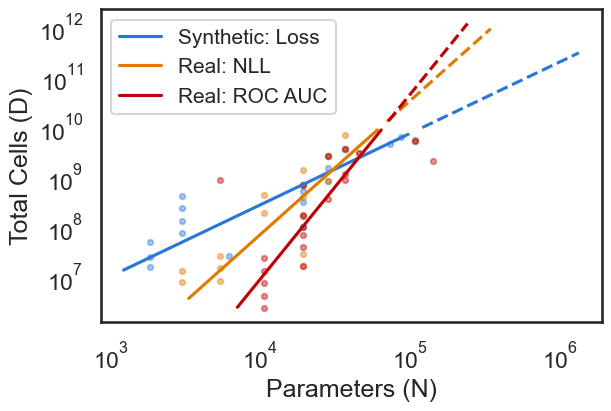

In [8]:
# Compute-optimal (N, D) path per metric: power laws N = A * C^a, D = B * C^b fitted on each Pareto front,
# evaluated at FLOP_VALUES and drawn in the (Parameters, Total Cells) plane
nd_metrics = {
    'val/val_loss':      {"color": "#2a78d6", "label": "Synthetic: Loss"},
    'real_data/nll':     {"color": "#e07b00", "label": "Real: NLL"},
    'real_data/roc_auc': {"color": "#bf0006", "label": "Real: ROC AUC"},
}

fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for loss_column, style in nd_metrics.items():
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)

    fits = {}
    for target in ["parameters", "total_cells"]:
        s, i, _, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto[target]))
        fits[target] = (np.exp(i), s)
    N_pred = fits["parameters"][0] * FLOP_VALUES ** fits["parameters"][1]
    D_pred = fits["total_cells"][0] * FLOP_VALUES ** fits["total_cells"][1]

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax.scatter(pareto["parameters"], pareto["total_cells"], color=style["color"], alpha=0.4, s=15)
    ax.plot(N_pred[in_range], D_pred[in_range], linestyle="-", color=style["color"], label=f"{style['label']}")
    ax.plot(N_pred[~in_range], D_pred[~in_range], linestyle="--", color=style["color"])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Parameters (N)")
ax.set_ylabel("Total Cells (D)")
ax.legend(fontsize="small")

fig.savefig(save_path / "compute_optimal_nd_paths.pdf")
print(f"Saving {save_path / 'compute_optimal_nd_paths.pdf'}")


Saving /Users/hogj/Documents/tabular/tfm-scaling-laws/playground/figures/compute_optimal_flops_vs_parameters.pdf


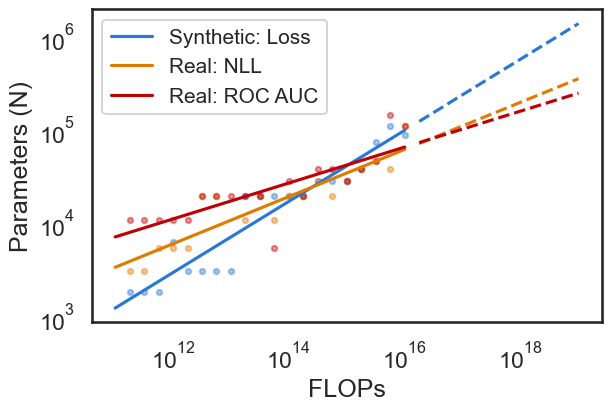

In [9]:
# Compute-optimal Parameters (N) vs FLOPs per metric: power law parameters = A * C^a fitted on each Pareto front,
# evaluated at FLOP_VALUES; solid within the front's FLOP range, dashed beyond
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for loss_column, style in nd_metrics.items():
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)

    s, i, r, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto["parameters"]))
    y_pred = np.exp(i) * FLOP_VALUES ** s

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax.scatter(pareto[flops_column], pareto["parameters"], color=style["color"], alpha=0.4, s=15)
    ax.plot(FLOP_VALUES[in_range], y_pred[in_range], linestyle="-", color=style["color"],
            label=f"{style['label']}")#: $\\propto C^{{{s:.2f}}}$")
    ax.plot(FLOP_VALUES[~in_range], y_pred[~in_range], linestyle="--", color=style["color"])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("FLOPs")
ax.set_ylabel("Parameters (N)")
ax.legend(fontsize="small")

fig.savefig(save_path / "compute_optimal_flops_vs_parameters.pdf")
print(f"Saving {save_path / 'compute_optimal_flops_vs_parameters.pdf'}")


Saving /Users/hogj/Documents/tabular/tfm-scaling-laws/playground/figures/compute_optimal_flops_vs_total_cells.pdf


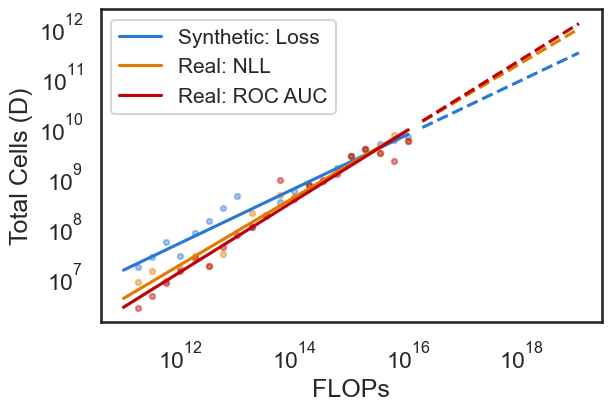

In [10]:
# Compute-optimal Total Cells (D) vs FLOPs per metric: power law total_cells = A * C^a fitted on each Pareto front,
# evaluated at FLOP_VALUES; solid within the front's FLOP range, dashed beyond
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for loss_column, style in nd_metrics.items():
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)

    s, i, r, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto["total_cells"]))
    y_pred = np.exp(i) * FLOP_VALUES ** s

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax.scatter(pareto[flops_column], pareto["total_cells"], color=style["color"], alpha=0.4, s=15)
    ax.plot(FLOP_VALUES[in_range], y_pred[in_range], linestyle="-", color=style["color"],
            label=f"{style['label']}")  #: $\\propto C^{{{s:.2f}}}$")
    ax.plot(FLOP_VALUES[~in_range], y_pred[~in_range], linestyle="--", color=style["color"])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("FLOPs")
ax.set_ylabel("Total Cells (D)")
ax.legend(fontsize="small")

fig.savefig(save_path / "compute_optimal_flops_vs_total_cells.pdf")
print(f"Saving {save_path / 'compute_optimal_flops_vs_total_cells.pdf'}")


## Figure 3: prior ablation (top row) and prior size against compute (bottom row)


Saving /Users/hogj/Documents/tabular/tfm-scaling-laws/playground/figures/prior_ablation.pdf


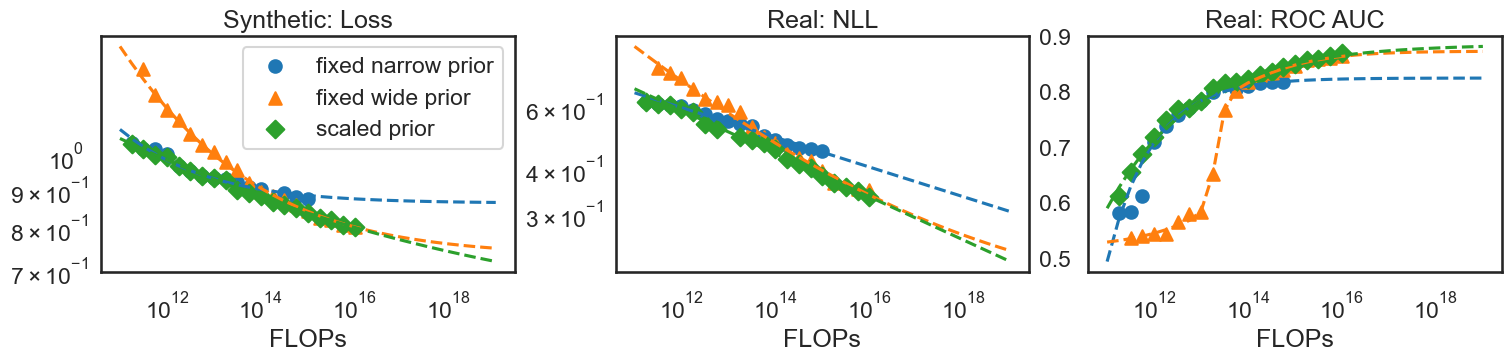

In [11]:

small_prior = {
    "name": "fixed narrow prior",
    "marker": "o",
    "config/max_features": 4,
    "config/num_datapoints_max": 100,
}
big_prior = {
    "name": "fixed wide prior",
    "marker": "^",
    "config/max_features": 16,
    "config/num_datapoints_max": 400,
}

all_data_prior = {
    "name": "scaled prior",
    "marker": "D",
}
eval_settings = [small_prior, big_prior, all_data_prior]

n_cols = len(custom_metrics)
fig, axes = plt.subplots(1, n_cols, layout='constrained', figsize=(5 * n_cols, 3.5), squeeze=False)

for loss_idx, loss_column in enumerate(custom_metrics):
    ax = axes[0, loss_idx]
    maximization = "roc_auc" in loss_column or "accuracy" in loss_column
    minimization = not maximization
    
    for eval_setting in eval_settings:
        initial_grid = initial_grid_min
        bounds = None
        func_form = functional_form_L0

        sigmoid_flag = False
        if loss_column == "real_data/roc_auc" and eval_setting["name"] == big_prior["name"]:
            sigmoid_flag = True
            initial_grid = initial_grid_double_sigmoid
            bounds = bounds_double_sigmoid
            func_form = double_sigmoid_functional_form

        eval_setting = eval_setting.copy()
        label = eval_setting.pop("name")
        marker = eval_setting.pop("marker")
        setting_df = df.copy()
        for column, value in eval_setting.items():
            setting_df = setting_df[setting_df[column] == value]

        pareto = get_pareto_frontier(setting_df, flops_column, loss_column, minimization=minimization)

        ax.scatter(pareto[flops_column], pareto[loss_column], label=label, marker=marker)

        X_data = pareto[flops_column].values
        y_data = np.log(pareto[loss_column].values) if minimization else np.log(1 - pareto[loss_column].values)
        if sigmoid_flag:
            y_data = pareto[loss_column].values

        best_params, best_loss = fit_parametric_form(
            func_form=func_form,
            x_data=X_data,
            y_data=y_data,
            initial_grid=list(product(*initial_grid)),
            bounds=bounds,
            delta=1e-3,
        )

        y_pred = func_form(FLOP_VALUES, best_params, return_log_loss=False)
        y_pred = y_pred if minimization else 1 - y_pred
        if sigmoid_flag:
            y_pred = 1 - y_pred
        ax.plot(FLOP_VALUES, y_pred, linestyle="--")

        # the scaled prior is the setting with no config filters
        if label == all_data_prior["name"]:
            scaled_pareto = pareto.sort_values(by=flops_column)

        if loss_idx == 0:
            ax.legend()

    ax.set_xscale("log")
    ax.set_xlabel("FLOPs")
    ax.set_title(custom_labels.get(loss_column, loss_column))
    if minimization:
        ax.set_yscale("log")

fig.savefig(save_path / "prior_ablation.pdf")
print(f"Saving {save_path / 'prior_ablation.pdf'}")


/var/folders/9v/1vzj07p55p389cb0_mh28p6h0000gp/T/ipykernel_13009/3516519399.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_optimal[y_name] = - df_optimal[y_name]


val/val_loss         config/num_datapoints_max      vs total_flops_rounded    A=0.474  alpha=0.1940  R2=0.878
val/val_loss         config/max_features            vs total_flops_rounded    A=0.119  alpha=0.1251  R2=0.434
val/val_loss         prior_max_cells                vs total_flops_rounded    A=0.0565  alpha=0.3191  R2=0.765
real_data/nll        config/num_datapoints_max      vs total_flops_rounded    A=0.862  alpha=0.1875  R2=0.859
real_data/nll        config/max_features            vs total_flops_rounded    A=0.141  alpha=0.1177  R2=0.424
real_data/nll        prior_max_cells                vs total_flops_rounded    A=0.121  alpha=0.3052  R2=0.770
real_data/roc_auc    config/num_datapoints_max      vs total_flops_rounded    A=0.201  alpha=0.2246  R2=0.841
real_data/roc_auc    config/max_features            vs total_flops_rounded    A=0.0112  alpha=0.1928  R2=0.864
real_data/roc_auc    prior_max_cells                vs total_flops_rounded    A=0.00226  alpha=0.4174  R2=0.944


Saving /Users/hogj/Documents/tabular/tfm-scaling-laws/playground/figures/prior_size_scaling.pdf


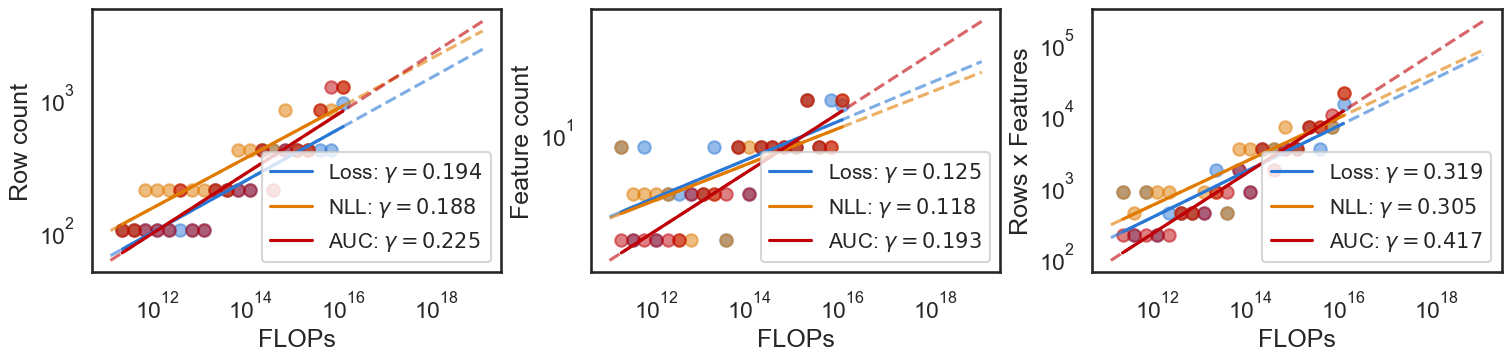

In [12]:
# Power-law fits (no floor): prior size = A * FLOPs^alpha, fitted as a line in log-log space.
# Rows and columns of the prior are free only in the scaled-prior setting, so the fit uses the
# unfiltered df. One fit per metric so the exponents can be compared.
USE_PARETO = False   # True: get_pareto_frontier (strictly improving front); False: get_optimal_values (best per FLOP level)
DEBUG_LEGEND = False  # True: full fit form (A, alpha, R^2) in the legend; False: only alpha
SHOW_PRIOR_RATIO = False  # True: third panel fitting prior_ratio (rows / features) vs parameters
SHOW_PRIOR_RATIO_CELLS = False  # True: fourth panel fitting prior_ratio vs total_cells
SHOW_PRIOR_MAX_CELLS = True  # True: panel fitting prior_max_cells (rows * features) vs FLOPs
frontier_fn = get_pareto_frontier if USE_PARETO else get_optimal_values

prior_fit_metrics = ['val/val_loss', 'real_data/nll', 'real_data/roc_auc']
prior_fit_colors = {'val/val_loss': "#2a78d6", 'real_data/nll': "#e07b00", 'real_data/roc_auc': "#bf0006"}
prior_fit_names = {'val/val_loss': "Loss", 'real_data/nll': "NLL", 'real_data/roc_auc': "AUC"}
# (y column, y label, x column, x label, x grid for the fitted line)
PARAM_VALUES = np.logspace(np.log10(df["parameters"].min()), np.log10(df["parameters"].max()), 200)
CELL_VALUES = np.logspace(np.log10(df["total_cells"].min()), np.log10(df["total_cells"].max()), 200)
prior_axes = [
    ("config/num_datapoints_max", "Row count", flops_column, "FLOPs", FLOP_VALUES),
    ("config/max_features", "Feature count", flops_column, "FLOPs", FLOP_VALUES),
]
if SHOW_PRIOR_RATIO:
    prior_axes.append(("prior_ratio", "Rows / Features", "parameters", "Parameters", PARAM_VALUES))
if SHOW_PRIOR_RATIO_CELLS:
    prior_axes.append(("prior_ratio", "Rows / Features", "total_cells", "Total Cells", CELL_VALUES))
if SHOW_PRIOR_MAX_CELLS:
    prior_axes.append(("prior_max_cells", "Rows x Features", flops_column, "FLOPs", FLOP_VALUES))

fig, axes = plt.subplots(1, len(prior_axes), layout='constrained', figsize=(5 * len(prior_axes), 3.5))
axes[1].sharex(axes[0])
prior_slopes = {}

for loss_column in prior_fit_metrics:
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    front = frontier_fn(df, flops_column, loss_column, minimization=minimization).sort_values(by=flops_column)

    for ax, (prior_column, prior_label, x_column, x_label, x_grid) in zip(axes, prior_axes):
        slope, intercept, r_value, p_value, std_err = fit_linear_model(
            np.log(front[x_column]), np.log(front[prior_column])
        )
        prior_slopes[(loss_column, prior_column, x_column)] = (np.exp(intercept), slope, r_value ** 2)

        color = prior_fit_colors[loss_column]
        if DEBUG_LEGEND:
            fit_label = f"{loss_column}: $A={np.exp(intercept):.2g}$, $\\gamma={slope:.3f}$, $R^2={r_value ** 2:.2f}$"
        else:
            fit_label = f"{prior_fit_names[loss_column]}: $\\gamma={slope:.3f}$"
        ax.scatter(front[x_column], front[prior_column], marker='o', color=color, alpha=0.5,
                   label=loss_column if DEBUG_LEGEND else None)
        # solid within the front's x range, dashed where the fit extrapolates
        y_fit = np.exp(intercept) * x_grid ** slope
        in_range = (x_grid >= front[x_column].min()) & (x_grid <= front[x_column].max())
        ax.plot(x_grid[in_range], y_fit[in_range], linestyle="-", color=color, label=fit_label)
        ax.plot(x_grid[~in_range], y_fit[~in_range], linestyle="--", color=color, alpha=0.6)
        ax.set_ylabel(prior_label)
        ax.set_xlabel(x_label)

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.legend(fontsize="small", loc="lower right")
# fig.suptitle(f"Prior Size vs FLOPs")

for (loss_column, prior_column, x_column), (A, alpha, r2) in prior_slopes.items():
    print(f"{loss_column:20s} {prior_column:30s} vs {x_column:22s} A={A:.3g}  alpha={alpha:.4f}  R2={r2:.3f}")


fig.savefig(save_path / "prior_size_scaling.pdf")
print(f"Saving {save_path / 'prior_size_scaling.pdf'}")
